# Step 4b — Pilot: Does Group Size Create Variation in Exact Retrieval?

**Why this pilot:** in the main step-4 experiment (5 images per group), 82 of 84 groups had **no** exactly stable images, so exact retrieval accuracy sat at the floor (≈0.3–0.5%).
This pilot checks whether **smaller groups (2, 3, 4 images)** bring exact retrieval off the floor, before running a full experiment.

**Unchanged from step 4:**
- Hopfield learning and update rules (`src/hopfield.py`)
- the typical-image pool (476 images)
- 5 different digits per group → here *k* different digits per group
- corruption levels 0%, 5%, 10%, 20%, with 20 trials per image per level
- the mutually exclusive outcome categories, with non-convergence checked first

**Pilot size:** 3 group sizes × 3 overlap levels × 4 groups = **36 groups**, about 4,300 recalls (a minute or two).
A pilot is too small for firm statistics. Its purpose is to show whether there is **variation worth measuring**.

In [1]:
import sys, json, time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.optdigits import load_optdigits
from src.hopfield import train_hebbian, recall, is_fixed_point, corrupt, overlap   # rules unchanged

RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(exist_ok=True)

images, labels = load_optdigits()
N = 32 * 32
patterns = 2.0 * images.reshape(len(images), N) - 1.0
M_all = patterns @ patterns.T / N

# Typical-image pool: identical definition to notebooks 02 and 04
# (typicality = mean overlap with the other images of the same digit; keep images at/above their digit's median)
typicality = np.zeros(len(labels))
for i in range(len(labels)):
    same = labels == labels[i]; same[i] = False
    typicality[i] = M_all[i, same].mean()
in_pool = np.zeros(len(labels), dtype=bool)
for d in range(10):
    idx_d = np.where(labels == d)[0]
    in_pool[idx_d] = typicality[idx_d] >= np.median(typicality[idx_d])
pool = np.where(in_pool)[0]
pool_by_digit = [pool[labels[pool] == d] for d in range(10)]
assert len(pool) == 476
print("typical pool:", len(pool), "images")

typical pool: 476 images


In [2]:
RECOMPUTE = False

PILOT = dict(
    SAMPLING_SEED     = 3030,
    TRIAL_SEED        = 3031,
    GROUP_SIZES       = [2, 3, 4],
    N_CANDIDATES      = 50_000,        # random candidate groups per group size
    LEVEL_PERCENTILES = {"low": [0, 10], "medium": [45, 55], "high": [90, 100]},
    GROUPS_PER_LEVEL  = 4,
    CORRUPTION_LEVELS = [0.00, 0.05, 0.10, 0.20],
    TRIALS_PER_IMAGE  = 20,
    MAX_SWEEPS        = 100,
)
LEVELS = PILOT["CORRUPTION_LEVELS"]
OVERLAP_LEVELS = list(PILOT["LEVEL_PERCENTILES"])
PILOT

{'SAMPLING_SEED': 3030,
 'TRIAL_SEED': 3031,
 'GROUP_SIZES': [2, 3, 4],
 'N_CANDIDATES': 50000,
 'LEVEL_PERCENTILES': {'low': [0, 10], 'medium': [45, 55], 'high': [90, 100]},
 'GROUPS_PER_LEVEL': 4,
 'CORRUPTION_LEVELS': [0.0, 0.05, 0.1, 0.2],
 'TRIALS_PER_IMAGE': 20,
 'MAX_SWEEPS': 100}

## 1. Defining low / medium / high overlap for each group size

The spread of mean pairwise overlap depends on group size. A pair of images (one overlap value) varies much more than the mean of the 6 overlaps in a group of 4.
So one fixed set of thresholds would not mean the same thing for every size.

**Definition:** for each group size *k*:
1. Generate 50,000 random groups of *k* typical images with *k* different digits, using the same procedure as step 4.
2. Compute each group's mean pairwise overlap.
3. Define the levels by **percentiles of that size's own distribution**:
   - **low** = bottom 10% (0th–10th percentile)
   - **medium** = middle 10% (45th–55th percentile)
   - **high** = top 10% (90th–100th percentile)
4. Draw 4 groups at random from each level.

So "low" means "unusually dissimilar **for a group of that size**". The table below also gives the **absolute** overlap range of each level, which is needed when comparing sizes.

In [3]:
def mean_pairwise_overlap(idx):
    return float(np.mean([M_all[a, b] for a, b in combinations(idx, 2)]))

def random_candidates(k, n, rng):
    """n random groups of k typical images with k different digits (deduplicated)."""
    cands = {}
    for _ in range(n):
        digits = rng.choice(10, size=k, replace=False)
        idx = tuple(sorted(int(rng.choice(pool_by_digit[d])) for d in digits))
        if idx not in cands:
            cands[idx] = mean_pairwise_overlap(idx)
    return list(cands.keys()), np.array(list(cands.values()))

samp_rng = np.random.default_rng(PILOT["SAMPLING_SEED"])
groups, level_table, cand_dists = [], [], {}
for k in PILOT["GROUP_SIZES"]:
    cand_idx, cand_m = random_candidates(k, PILOT["N_CANDIDATES"], samp_rng)
    cand_dists[k] = cand_m
    for lvl, (p_lo, p_hi) in PILOT["LEVEL_PERCENTILES"].items():
        lo, hi = np.percentile(cand_m, [p_lo, p_hi])
        members = np.where((cand_m >= lo) & (cand_m <= hi))[0]
        chosen = samp_rng.choice(members, size=PILOT["GROUPS_PER_LEVEL"], replace=False)
        for c in sorted(chosen):
            groups.append(dict(group_id=len(groups), size=k, level=lvl,
                               idx=np.array(cand_idx[c]), mean_overlap=cand_m[c]))
        level_table.append(dict(size=k, level=lvl, percentiles=f"{p_lo}–{p_hi}",
                                overlap_from=round(lo, 3), overlap_to=round(hi, 3), candidates=len(members)))

print(f"{len(groups)} pilot groups")
pd.DataFrame(level_table)

36 pilot groups


,size,level,percentiles,overlap_from,overlap_to,candidates
0,2,low,0–10,0.084,0.330,3998
1,2,medium,45–55,0.453,0.479,4350
2,2,high,90–100,0.586,0.807,4086
3,3,low,0–10,0.230,0.383,5132
4,3,medium,45–55,0.454,0.470,5376
5,3,high,90–100,0.542,0.720,5112
6,4,low,0–10,0.289,0.403,5000
7,4,medium,45–55,0.456,0.467,5105
8,4,high,90–100,0.522,0.653,5017


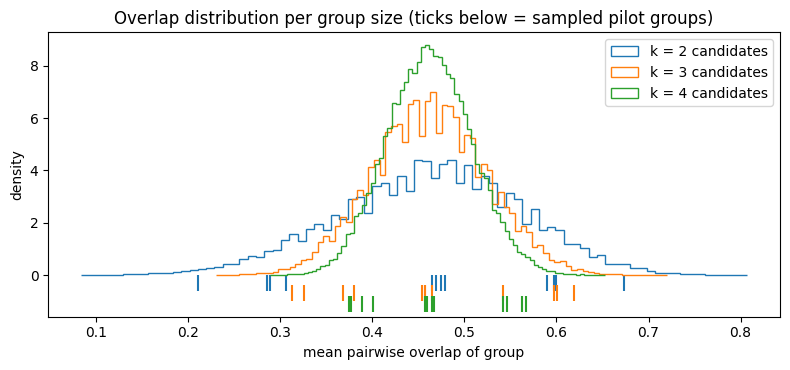

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, c in zip(PILOT["GROUP_SIZES"], ["tab:blue", "tab:orange", "tab:green"]):
    ax.hist(cand_dists[k], bins=80, histtype="step", density=True, color=c, label=f"k = {k} candidates")
    gm = [g["mean_overlap"] for g in groups if g["size"] == k]
    ax.scatter(gm, np.full(len(gm), -0.3 - 0.4 * PILOT["GROUP_SIZES"].index(k)), color=c, marker="|", s=120)
ax.set_xlabel("mean pairwise overlap of group"); ax.set_ylabel("density")
ax.set_title("Overlap distribution per group size (ticks below = sampled pilot groups)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Protocol (same as step 4)

For each group: store its *k* images. For each corruption level, each image and each of 20 trials, recall and classify the final state.
The categories are checked in this order and are mutually exclusive: `not_converged` → `correct` → `wrong_memory` → `mirror` → `other_attractor`.

**Extra for this pilot: do different images end in the same attractor?**
Every final state is recorded by a fingerprint of its exact pixel values.
For each group and corruption level, two stored images **share an attractor** if at least one trial starting from image *a* and one starting from image *b* ended in the **identical** state.
We report:
- `n_distinct_final`: how many different final states the group's trials reached
- `frac_pairs_shared`: the fraction of image pairs that share an attractor
- `all_merged`: True if every stored image only ever reached one single, common final state

This detects merging **without** counting any blend as a stored memory.

In [5]:
CATEGORIES = ["correct", "wrong_memory", "mirror", "other_attractor", "not_converged"]

def classify(res, target_pos, stored):
    """Identical to notebook 04."""
    if not res["converged"]:
        return "not_converged"
    s = res["state"]
    if np.array_equal(s, stored[target_pos]):
        return "correct"
    for k in range(len(stored)):
        if k != target_pos and np.array_equal(s, stored[k]):
            return "wrong_memory"
    for k in range(len(stored)):
        if np.array_equal(s, -stored[k]):
            return "mirror"
    return "other_attractor"

def fingerprint(state):
    """Exact identity of a ±1 state, as a short hashable string."""
    return (state > 0).tobytes().hex()

def run_group(g, rng):
    idx = g["idx"]
    stored = patterns[idx]
    for a, b in combinations(range(len(idx)), 2):
        assert not np.array_equal(stored[a], stored[b]) and not np.array_equal(stored[a], -stored[b])
    W = train_hebbian(stored)
    stable = np.array([is_fixed_point(W, p) == 1.0 for p in stored])
    rows = []
    for level in LEVELS:
        for pos in range(len(idx)):
            for t in range(PILOT["TRIALS_PER_IMAGE"]):
                res = recall(W, corrupt(stored[pos], level, rng), rng, max_sweeps=PILOT["MAX_SWEEPS"])
                rows.append(dict(group_id=g["group_id"], size=g["size"], level_name=g["level"],
                                 mean_overlap=g["mean_overlap"], image_pos=pos, image_index=int(idx[pos]),
                                 corruption=level, trial=t, outcome=classify(res, pos, stored),
                                 final_overlap_target=overlap(res["state"], stored[pos]),
                                 final_state=fingerprint(res["state"]),
                                 sweeps=res["sweeps"], converged=res["converged"]))
    return rows, stable

In [6]:
TRIALS_CSV = RESULTS_DIR / "pilot_groupsize_trials.csv"
GROUPS_CSV = RESULTS_DIR / "pilot_groupsize_groups.csv"
CONFIG_JSON = RESULTS_DIR / "pilot_groupsize_config.json"

def saved_config_matches():
    return CONFIG_JSON.exists() and json.loads(CONFIG_JSON.read_text()) == json.loads(json.dumps(PILOT))

if RECOMPUTE or not (TRIALS_CSV.exists() and GROUPS_CSV.exists() and saved_config_matches()):
    t0 = time.time()
    seeds = np.random.SeedSequence(PILOT["TRIAL_SEED"]).spawn(len(groups))   # one stream per group
    all_rows, info = [], []
    for g, ss in zip(groups, seeds):
        rows, stable = run_group(g, np.random.default_rng(ss))
        all_rows += rows
        info.append(dict(group_id=g["group_id"], size=g["size"], level=g["level"], mean_overlap=g["mean_overlap"],
                         images=" ".join(map(str, g["idx"])), digits=" ".join(map(str, labels[g["idx"]])),
                         n_stable=int(stable.sum())))
    trials = pd.DataFrame(all_rows)
    ginfo = pd.DataFrame(info)
    trials.to_csv(TRIALS_CSV, index=False); ginfo.to_csv(GROUPS_CSV, index=False)
    CONFIG_JSON.write_text(json.dumps(PILOT, indent=2))
    print(f"pilot ran in {time.time() - t0:.0f} s, saved to {RESULTS_DIR}")
else:
    trials, ginfo = pd.read_csv(TRIALS_CSV), pd.read_csv(GROUPS_CSV)
    print("loaded saved pilot results")

assert np.allclose(ginfo.mean_overlap.values, [g["mean_overlap"] for g in groups])
print(f"{len(ginfo)} groups, {len(trials):,} trials, non-converged: {(trials.outcome == 'not_converged').sum()}")

loaded saved pilot results
36 groups, 8,640 trials, non-converged: 0


## 3. Per-group summary

One row per group **and** corruption level (the group is still the unit of analysis):
- `stable_frac`: fraction of stored images that are exact fixed points
- `accuracy`: fraction of trials that end **exactly** at the target
- `mean_final_overlap`: mean overlap of the final state with the target. This is reported **separately** and does not count as retrieval.
- the attractor-sharing measures defined above

In [7]:
def attractor_sharing(t):
    """Measures of whether different stored images end in the same final state(s)."""
    finals = t.groupby("image_pos")["final_state"].apply(set)
    pos = list(finals.index)
    pairs = list(combinations(pos, 2))
    shared = [len(finals[a] & finals[b]) > 0 for a, b in pairs]
    all_states = set().union(*finals.values)
    return dict(n_distinct_final=len(all_states),
                frac_pairs_shared=float(np.mean(shared)),
                all_merged=(len(all_states) == 1))

rows = []
for (gid, corr), t in trials.groupby(["group_id", "corruption"]):
    gi = ginfo.set_index("group_id").loc[gid]
    row = dict(group_id=gid, size=gi["size"], level=gi["level"], mean_overlap=gi["mean_overlap"],
               corruption=corr, stable_frac=gi["n_stable"] / gi["size"],
               accuracy=(t.outcome == "correct").mean(),
               mean_final_overlap=t.final_overlap_target.mean())
    for c in CATEGORIES:
        row[c] = (t.outcome == c).mean()
    row.update(attractor_sharing(t))
    rows.append(row)
summary = pd.DataFrame(rows)

# Checks: categories are exhaustive, and 0% accuracy == clean stability (as in step 4)
assert np.allclose(summary[CATEGORIES].sum(axis=1), 1.0)
s0 = summary[summary.corruption == 0]
assert np.allclose(s0.accuracy, s0.stable_frac)
print("summary checks passed")

summary checks passed


## 4. Five-memory baseline (from step 4)

For comparison, load the saved step-4 results and assign each of its 84 groups to low / medium / high using **the same percentile rule** applied to the size-5 candidate distribution.
Step-4 groups were stratified by absolute bins, not percentiles, so the number of baseline groups at each level is uneven. Groups outside all three ranges are dropped from this comparison.

The step-4 trial file did not record final-state fingerprints, so attractor sharing is not available for the baseline (step 3 showed the hand-picked HIGH group merging into one state).

In [8]:
base = pd.read_csv(RESULTS_DIR / "step4_groups.csv")
_, cand5 = random_candidates(5, PILOT["N_CANDIDATES"], np.random.default_rng(PILOT["SAMPLING_SEED"] + 5))

def level_of(m, dist):
    for lvl, (p_lo, p_hi) in PILOT["LEVEL_PERCENTILES"].items():
        lo, hi = np.percentile(dist, [p_lo, p_hi])
        if lo <= m <= hi:
            return lvl
    return None

base["level"] = [level_of(m, cand5) for m in base.mean_overlap]
base_rows = []
for _, r in base.dropna(subset=["level"]).iterrows():
    for corr in LEVELS:
        c = int(corr * 100)
        base_rows.append(dict(group_id=f"s4_{r.group_id}", size=5, level=r.level, mean_overlap=r.mean_overlap,
                              corruption=corr, stable_frac=r.n_stable / 5,
                              accuracy=r[f"correct_{c}"], mean_final_overlap=r[f"mean_final_overlap_{c}"],
                              **{cat: r[f"{cat}_{c}"] for cat in CATEGORIES}))
baseline = pd.DataFrame(base_rows)
print("baseline groups per level:", baseline[baseline.corruption == 0].level.value_counts().to_dict())

combined = pd.concat([summary, baseline], ignore_index=True)

baseline groups per level: {'low': 26, 'high': 26, 'medium': 3}


## 5. Results

### 5a. Exact retrieval accuracy (mean over groups)
Rows: group size and overlap level. Columns: corruption level. The 0% column equals clean stability.

In [9]:
def table(col):
    t = combined.pivot_table(index=["size", "level"], columns="corruption", values=col, aggfunc="mean")
    t = t.reindex(OVERLAP_LEVELS, level="level")
    t.columns = [f"{int(c*100)}%" for c in t.columns]
    return t

n_groups = combined[combined.corruption == 0].groupby(["size", "level"]).size().rename("n_groups")
acc_table = table("accuracy").join(n_groups)
acc_table.round(3)

0%     5%    10%    20%  n_groups
size level                                       
2    low     1.000  1.000  1.000  1.000         4
     medium  1.000  1.000  1.000  1.000         4
     high    1.000  1.000  1.000  1.000         4
3    low     1.000  1.000  1.000  0.992         4
     medium  0.833  0.825  0.767  0.700         4
     high    0.000  0.000  0.000  0.000         4
4    low     0.188  0.172  0.162  0.106         4
     medium  0.000  0.000  0.000  0.000         4
     high    0.000  0.000  0.000  0.000         4
5    low     0.015  0.010  0.010  0.009        26
     medium  0.000  0.000  0.000  0.000         3
     high    0.000  0.000  0.000  0.000        26

### 5b. Mean final overlap with the target (reported separately; not counted as retrieval)

In [10]:
table("mean_final_overlap").round(3)

0%     5%    10%    20%
size level                             
2    low     1.000  1.000  1.000  1.000
     medium  1.000  1.000  1.000  1.000
     high    1.000  1.000  1.000  1.000
3    low     1.000  1.000  1.000  0.999
     medium  0.970  0.968  0.954  0.938
     high    0.795  0.795  0.795  0.795
4    low     0.883  0.879  0.877  0.858
     medium  0.836  0.836  0.836  0.836
     high    0.839  0.839  0.839  0.839
5    low     0.729  0.726  0.725  0.723
     medium  0.693  0.693  0.693  0.691
     high    0.742  0.742  0.742  0.742

### 5c. How many groups have *any* exact retrieval?
A mean can hide whether accuracy is spread across groups or comes from one outlier, so count groups with accuracy > 0.

In [11]:
any_table = combined.assign(any_correct=combined.accuracy > 0).pivot_table(
    index=["size", "level"], columns="corruption", values="any_correct", aggfunc="sum")
any_table = any_table.reindex(OVERLAP_LEVELS, level="level")
any_table.columns = [f"{int(c*100)}%" for c in any_table.columns]
any_table.join(n_groups).astype(int)

0%  5%  10%  20%  n_groups
size level                             
2    low      4   4    4    4         4
     medium   4   4    4    4         4
     high     4   4    4    4         4
3    low      4   4    4    4         4
     medium   4   4    4    4         4
     high     0   0    0    0         4
4    low      3   3    3    3         4
     medium   0   0    0    0         4
     high     0   0    0    0         4
5    low      2   2    2    2        26
     medium   0   0    0    0         3
     high     0   0    0    0        26

### 5d. Do different stored images end in the same attractor?
Mean over groups (pilot sizes only). `frac_pairs_shared` = fraction of image pairs whose trials reached at least one identical final state.

In [12]:
share = summary.pivot_table(index=["size", "level"], columns="corruption",
                            values=["frac_pairs_shared", "all_merged"], aggfunc="mean")
share = share.reindex(OVERLAP_LEVELS, level="level")
share.columns = [f"{m} {int(c*100)}%" for m, c in share.columns]
share.round(2)

all_merged 0%  all_merged 5%  all_merged 10%  all_merged 20%  \
size level                                                                  
2    low               0.0            0.0             0.0             0.0   
     medium            0.0            0.0             0.0             0.0   
     high              0.0            0.0             0.0             0.0   
3    low               0.0            0.0             0.0             0.0   
     medium            0.0            0.0             0.0             0.0   
     high              1.0            1.0             1.0             1.0   
4    low               0.0            0.0             0.0             0.0   
     medium            0.0            0.0             0.0             0.0   
     high              0.0            0.0             0.0             0.0   

             frac_pairs_shared 0%  frac_pairs_shared 5%  \
size level                                                
2    low                     0.00                  0.00   
     medium                  0.00                  0.00   
     high                    0.00                  0.00   
3    low                     0.00                  0.00   
     medium                  0.00                  0.08   
     high                    1.00                  1.00   
4    low                     0.00                  0.00   
     medium                  0.00                  0.00   
     high                    0.08                  0.08   

             frac_pairs_shared 10%  frac_pairs_shared 20%  
size level                                                 
2    low                      0.00                   0.00  
     medium                   0.00                   0.00  
     high                     0.00                   0.00  
3    low                      0.00                   0.00  
     medium                   0.25                   0.50  
     high                     1.00                   1.00  
4    low                      0.00                   0.00  
     medium                   0.00                   0.04  
     high                     0.08                   0.08

### 5e. Plots

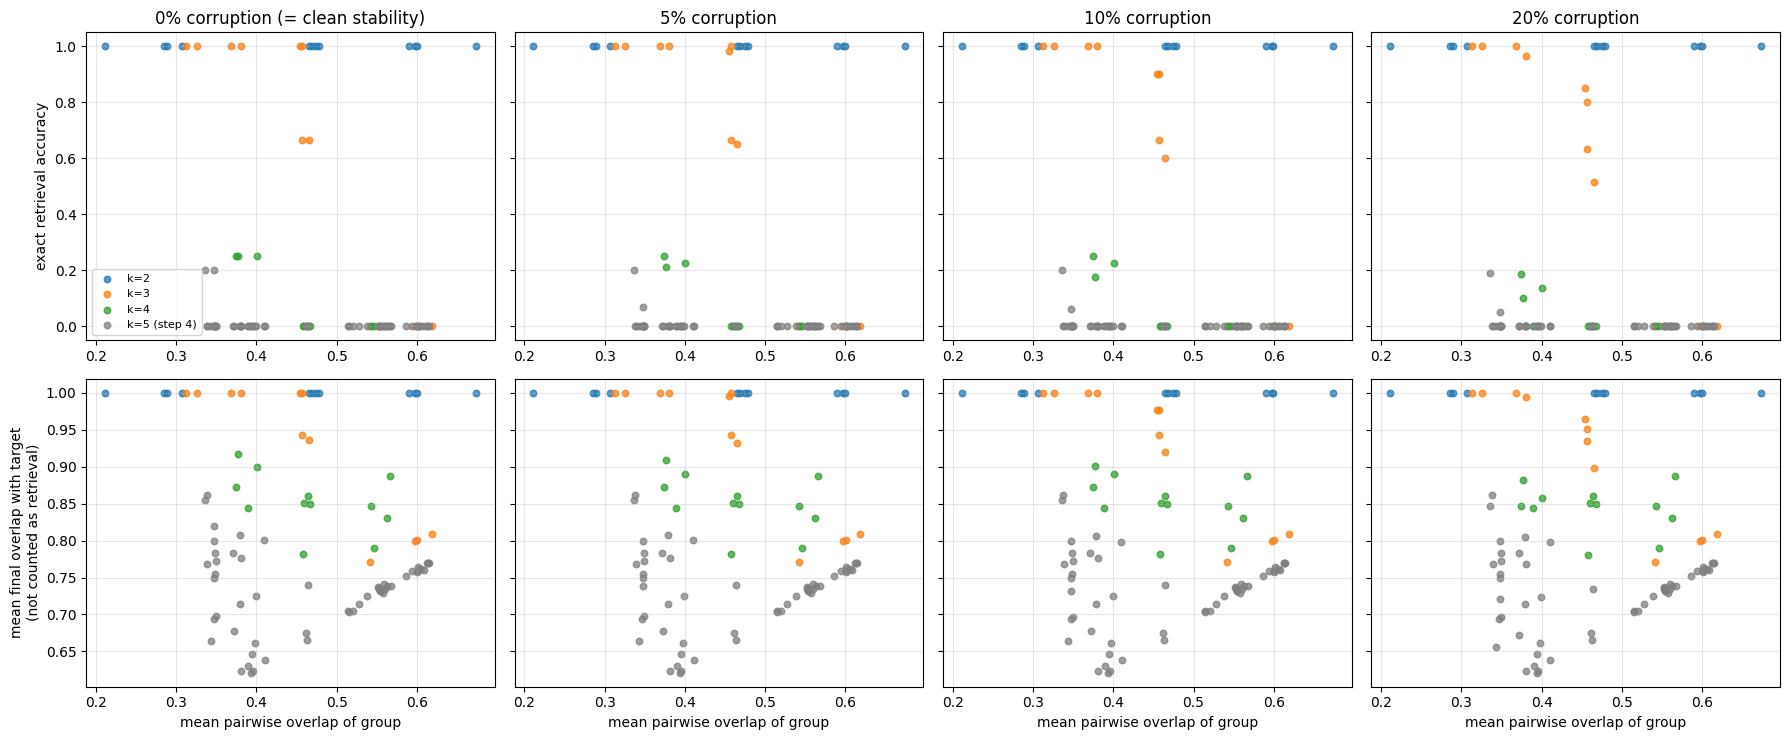

In [13]:
size_colors = {2: "tab:blue", 3: "tab:orange", 4: "tab:green", 5: "tab:gray"}
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharey="row")
for j, corr in enumerate(LEVELS):
    d = combined[combined.corruption == corr]
    for k, c in size_colors.items():
        dk = d[d["size"] == k]
        axes[0, j].scatter(dk.mean_overlap, dk.accuracy, color=c, s=22, alpha=0.75, label=f"k={k}" + (" (step 4)" if k == 5 else ""))
        axes[1, j].scatter(dk.mean_overlap, dk.mean_final_overlap, color=c, s=22, alpha=0.75)
    axes[0, j].set_title(f"{int(corr*100)}% corruption" + (" (= clean stability)" if corr == 0 else ""))
    axes[1, j].set_xlabel("mean pairwise overlap of group")
    for i in range(2):
        axes[i, j].grid(alpha=0.3)
axes[0, 0].set_ylabel("exact retrieval accuracy")
axes[1, 0].set_ylabel("mean final overlap with target\n(not counted as retrieval)")
axes[0, 0].legend(fontsize=8)
for ax in axes[0]:
    ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

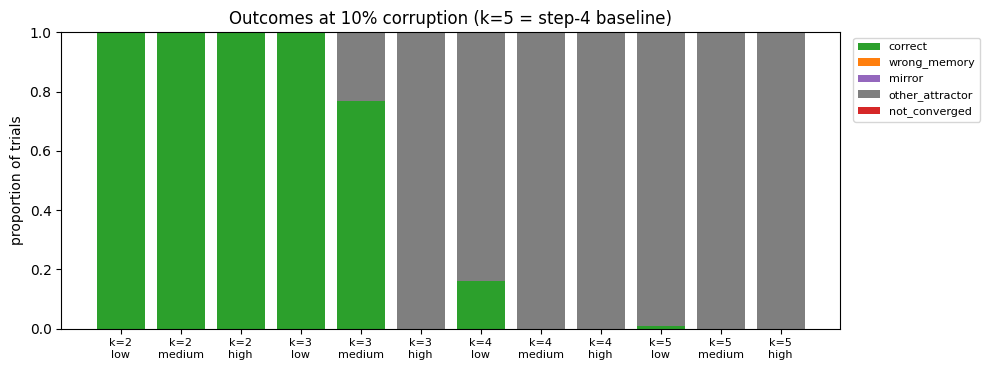

In [14]:
# Outcome breakdown at 10% corruption, mean over groups, per size and level
d = combined[combined.corruption == 0.10].groupby(["size", "level"])[CATEGORIES].mean()
d = d.reindex(OVERLAP_LEVELS, level="level")
colors = {"correct": "tab:green", "wrong_memory": "tab:orange", "mirror": "tab:purple",
          "other_attractor": "tab:gray", "not_converged": "tab:red"}
fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(d))
for cat in CATEGORIES:
    ax.bar(range(len(d)), d[cat].values, bottom=bottom, color=colors[cat], label=cat)
    bottom += d[cat].values
ax.set_xticks(range(len(d))); ax.set_xticklabels([f"k={s}\n{l}" for s, l in d.index], fontsize=8)
ax.set_ylabel("proportion of trials"); ax.set_title("Outcomes at 10% corruption (k=5 = step-4 baseline)")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()